# Sales Performance Analysis — Data Aggregation
**Dataset:** `retail_sales_dataset.csv` — transaction date, customer gender and age, product category, quantity sold and total sales amount.

> **Note:** this dataset has **no Region column**. Customer **Age Group** is used as the grouping variable in place of Region (set `SEGMENT_COL = "Gender"` in Task 3 to group by gender instead). Every step below works the same either way.

## 1. Import Libraries and Dataset

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter

plt.style.use("seaborn-v0_8-whitegrid")
plt.rcParams.update({"figure.dpi": 100, "axes.titlesize": 13, "axes.titleweight": "bold", "axes.labelsize": 11})
money = FuncFormatter(lambda x, _: f"{x:,.0f}")   # thousands separator for axes

df = pd.read_csv("retail_sales_dataset.csv")
df.head()

,Transaction ID,Date,Customer ID,Gender,Age,Product Category,Quantity,Price per Unit,Total Amount
0,1,2023-11-24,CUST001,Male,34,Beauty,3,50,150
1,2,2023-02-27,CUST002,Female,26,Clothing,2,500,1000
2,3,2023-01-13,CUST003,Male,50,Electronics,1,30,30
3,4,2023-05-21,CUST004,Male,37,Clothing,1,500,500
4,5,2023-05-06,CUST005,Male,30,Beauty,2,50,100


## 2. Explore the Dataset

In [2]:
print("Shape:", df.shape)
df.info()
print("\nMissing values:\n", df.isnull().sum())
print("\nDuplicate rows:", df.duplicated().sum())
df.describe().round(2)

Shape: (1000, 9)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 9 columns):
 #   Column            Non-Null Count  Dtype 
---  ------            --------------  ----- 
 0   Transaction ID    1000 non-null   int64 
 1   Date              1000 non-null   object
 2   Customer ID       1000 non-null   object
 3   Gender            1000 non-null   object
 4   Age               1000 non-null   int64 
 5   Product Category  1000 non-null   object
 6   Quantity          1000 non-null   int64 
 7   Price per Unit    1000 non-null   int64 
 8   Total Amount      1000 non-null   int64 
dtypes: int64(5), object(4)
memory usage: 70.4+ KB

Missing values:
 Transaction ID      0
Date                0
Customer ID         0
Gender              0
Age                 0
Product Category    0
Quantity            0
Price per Unit      0
Total Amount        0
dtype: int64

Duplicate rows: 0


,Transaction ID,Age,Quantity,Price per Unit,Total Amount
count,1000.00,1000.00,1000.00,1000.00,1000.0
mean,500.50,41.39,2.51,179.89,456.0
std,288.82,13.68,1.13,189.68,560.0
min,1.00,18.00,1.00,25.00,25.0
25%,250.75,29.00,1.00,30.00,60.0
50%,500.50,42.00,3.00,50.00,135.0
75%,750.25,53.00,4.00,300.00,900.0
max,1000.00,64.00,4.00,500.00,2000.0


## 3. Identify Relevant Variables and Clean the Data
The grouping variable `SEGMENT_COL` plays the role of *Region* in this analysis.

In [3]:
DATE_COL, CATEGORY_COL, QTY_COL, SALES_COL = "Date", "Product Category", "Quantity", "Total Amount"

# there is no Region column, so customers are grouped into age groups instead
df["Age Group"] = pd.cut(df["Age"], bins=[17, 25, 35, 45, 55, 100], labels=["18-25", "26-35", "36-45", "46-55", "56+"])
SEGMENT_COL = "Age Group"   # or "Gender"

df = df.drop_duplicates()[[DATE_COL, SEGMENT_COL, CATEGORY_COL, QTY_COL, SALES_COL]]
df[DATE_COL] = pd.to_datetime(df[DATE_COL], errors="coerce")
df[[QTY_COL, SALES_COL]] = df[[QTY_COL, SALES_COL]].apply(pd.to_numeric, errors="coerce")
df = df.dropna()

print(f"{SEGMENT_COL}s:", sorted(df[SEGMENT_COL].unique()))
print("Categories:", sorted(df[CATEGORY_COL].unique()))
print(f"Clean records: {len(df)}")

Age Groups: ['18-25', '26-35', '36-45', '46-55', '56+']
Categories: ['Beauty', 'Clothing', 'Electronics']
Clean records: 1000


## 4. Total Sales by Age Group

In [4]:
segment_sales = df.groupby(SEGMENT_COL, observed=True)[SALES_COL].sum().sort_values(ascending=False)
segment_sales.to_frame("Total Sales").style.format("{:,.2f}")

,Total Sales
Age Group,
46-55,"100,690.00"
26-35,"98,480.00"
36-45,"91,870.00"
18-25,"84,550.00"
56+,"80,410.00"


## 5. Sales Distribution by Age Group (Bar Plot and Pie Chart)

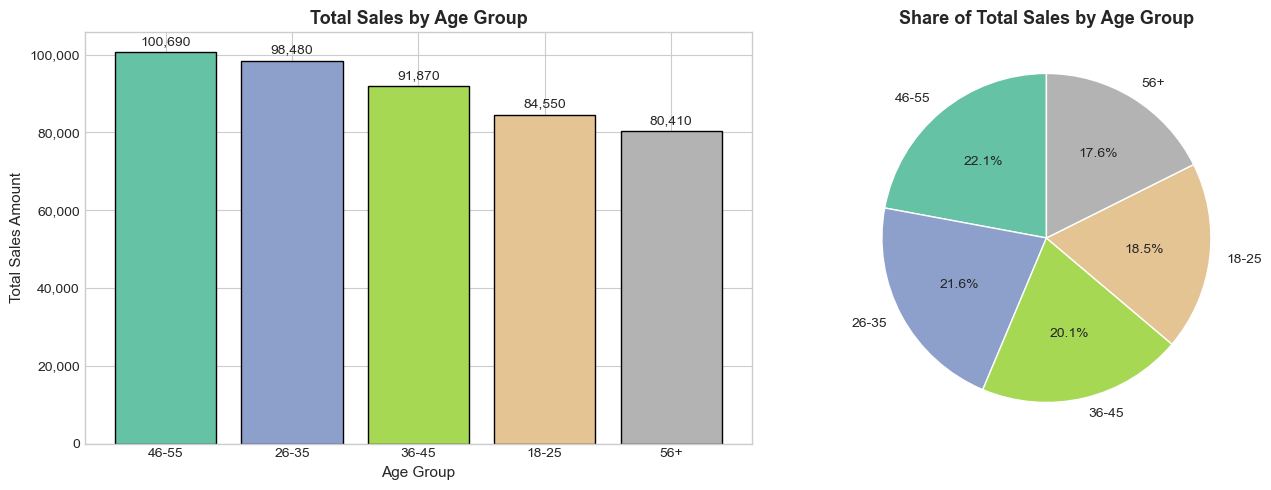

In [5]:
colors = plt.cm.Set2(np.linspace(0, 1, len(segment_sales)))
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Bar plot
bars = axes[0].bar(segment_sales.index, segment_sales.values, color=colors, edgecolor="black")
axes[0].bar_label(bars, labels=[f"{v:,.0f}" for v in segment_sales.values], padding=3)
axes[0].yaxis.set_major_formatter(money)
axes[0].set(title=f"Total Sales by {SEGMENT_COL}", xlabel=SEGMENT_COL, ylabel="Total Sales Amount")

# Pie chart
axes[1].pie(segment_sales, labels=segment_sales.index, autopct="%1.1f%%", startangle=90, colors=colors,
            wedgeprops={"edgecolor": "white"})
axes[1].set_title(f"Share of Total Sales by {SEGMENT_COL}")

plt.tight_layout()
plt.show()

## 6. Top-Performing Age Groups

,Total Sales,Share (%),Rank
Age Group,,,
46-55,"100,690.00",22.08,1
26-35,"98,480.00",21.60,2
36-45,"91,870.00",20.15,3
18-25,"84,550.00",18.54,4
56+,"80,410.00",17.63,5


Top 3 Age Groups: 46-55, 26-35, 36-45  (63.8% of total sales)


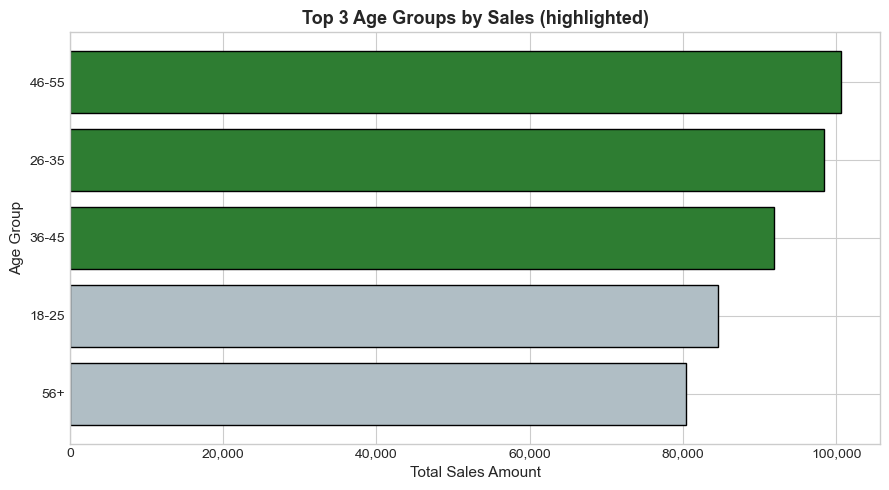

In [6]:
TOP_N = 3
summary = segment_sales.to_frame("Total Sales")
summary["Share (%)"] = (summary["Total Sales"] / summary["Total Sales"].sum() * 100).round(2)
summary["Rank"] = range(1, len(summary) + 1)
display(summary.style.format({"Total Sales": "{:,.2f}", "Share (%)": "{:.2f}"}))

top = segment_sales.head(TOP_N)
print(f"Top {TOP_N} {SEGMENT_COL}s: {', '.join(top.index)}  ({top.sum() / segment_sales.sum():.1%} of total sales)")

# Highlight the top groups
fig, ax = plt.subplots(figsize=(9, 5))
ax.barh(segment_sales.index[::-1], segment_sales.values[::-1],
        color=["#2e7d32" if r in top.index else "#b0bec5" for r in segment_sales.index[::-1]], edgecolor="black")
ax.xaxis.set_major_formatter(money)
ax.set(title=f"Top {TOP_N} {SEGMENT_COL}s by Sales (highlighted)", xlabel="Total Sales Amount", ylabel=SEGMENT_COL)
plt.tight_layout()
plt.show()

## 7. Sales by Age Group and Product Category

In [7]:
segment_cat = df.groupby([SEGMENT_COL, CATEGORY_COL], observed=True)[SALES_COL].sum()
pivot = segment_cat.unstack(fill_value=0).loc[segment_sales.index]   # ordered by total sales
pivot.style.format("{:,.2f}")

Product Category,Beauty,Clothing,Electronics
Age Group,,,
46-55,"34,720.00","30,485.00","35,485.00"
26-35,"31,240.00","39,975.00","27,265.00"
36-45,"28,405.00","29,550.00","33,915.00"
18-25,"31,280.00","26,510.00","26,760.00"
56+,"17,870.00","29,060.00","33,480.00"


## 8. Comparing Age Groups and Product Categories (Stacked and Grouped Bar Plots)

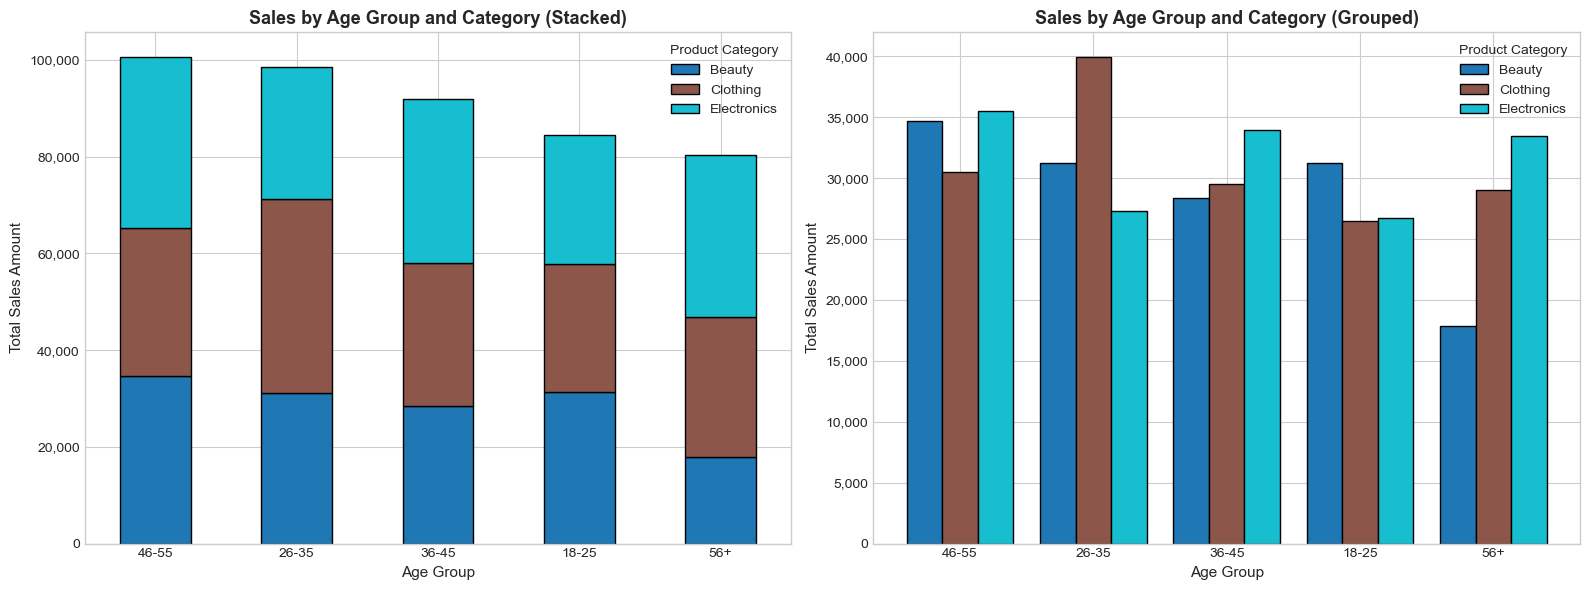

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Stacked bar plot
pivot.plot(kind="bar", stacked=True, ax=axes[0], colormap="tab10", edgecolor="black")
axes[0].set(title=f"Sales by {SEGMENT_COL} and Category (Stacked)", xlabel=SEGMENT_COL, ylabel="Total Sales Amount")

# Grouped bar plot
pivot.plot(kind="bar", ax=axes[1], colormap="tab10", edgecolor="black", width=0.8)
axes[1].set(title=f"Sales by {SEGMENT_COL} and Category (Grouped)", xlabel=SEGMENT_COL, ylabel="Total Sales Amount")

for ax in axes:
    ax.yaxis.set_major_formatter(money)
    ax.tick_params(axis="x", rotation=0)
    ax.legend(title="Product Category")
plt.tight_layout()
plt.show()

## 9. Key Insights

In [9]:
best_group = segment_sales.idxmax()
best_cat = pivot.loc[best_group].idxmax()
print(f"Top group           : {best_group} ({segment_sales.max():,.2f}, {segment_sales.max() / segment_sales.sum():.1%} of total)")
print(f"Lowest group        : {segment_sales.idxmin()} ({segment_sales.min():,.2f})")
print(f"Best category in {best_group}: {best_cat} ({pivot.loc[best_group, best_cat]:,.2f})")
print(f"Best category overall: {pivot.sum().idxmax()} ({pivot.sum().max():,.2f})")

Top group           : 46-55 (100,690.00, 22.1% of total)
Lowest group        : 56+ (80,410.00)
Best category in 46-55: Electronics (35,485.00)
Best category overall: Electronics (156,905.00)
